# 01 · Análisis exploratorio de datos (EDA)
## Demanda de turismo interno en Argentina

**Metodología: CRISP-DM.** Este notebook cubre la fase 2, **Comprensión de los datos**: qué hay, qué falta y qué llamó la atención, antes de preparar los datos (fase 3) y modelar (fase 4, `02_modelos.ipynb`). En términos de tipos de análisis, acá hacemos el análisis **descriptivo y diagnóstico** (¿qué pasó y por qué?); el predictivo y el prescriptivo vienen después.

**Hipótesis (una frase):** la demanda de turismo interno en Argentina se puede anticipar a partir del contexto económico de los hogares (salario real, inflación, desempleo, tipo de cambio), y eso le permite a la **Gerencia Comercial y Técnica** de una cadena hotelera / agencia de viajes planificar la temporada de verano con números en vez de a ojo.

**Fuentes (todas oficiales, descargadas una vez y usadas sin internet):**

| Dataset | Fuente | Qué aporta | Granularidad |
|---|---|---|---|
| `mensual.csv` | INDEC / SINTA — EOH | **Target:** viajeros residentes hospedados en hoteles y parahoteles | Mensual, 2007-01 → 2025-11 |
| | INDEC — IPC (San Luis + Nacional) | Inflación interanual | Mensual |
| | INDEC — ISO + Índice de salarios | Salario real (2017 = 100) | Trimestral → mensual |
| | BCRA — tipo de cambio A3500 | Tipo de cambio real (2017 = 100) | Diario → mensual |
| | INDEC — EMAE | Actividad económica, var. interanual | Mensual |
| | INDEC — EPH | Desocupación y pobreza | Trimestral / semestral |
| `evyth_turistas.csv` | SINTA — EVyTH (microdatos) | Quién viaja: quintil de ingreso, región, alojamiento | Un registro por turista y viaje, 2012 → 2024-T2 |

**Diccionario de columnas (dataset mensual):**

| Columna | Descripción |
|---|---|
| `viajeros_residentes` | Viajeros residentes hospedados en el mes (**target**) |
| `viajeros_no_residentes` | Viajeros extranjeros hospedados (contexto) |
| `inflacion_interanual` | Variación del IPC contra el mismo mes del año anterior (%) |
| `salario_real` | Salario nominal / IPC, índice 2017 = 100 |
| `tipo_cambio_real` | Tipo de cambio A3500 / IPC, índice 2017 = 100 (más alto = viajar al exterior es más caro) |
| `emae_interanual` | Actividad económica, variación interanual (%) |
| `desocupacion` | Tasa de desocupación (%) |
| `pobreza` | Personas bajo la línea de pobreza (%) |
| `pandemia` | `True` entre 2020-03 y 2021-12 |

## Preparación

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from modelos import cargar_mensual, cargar_evyth

pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="talk", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 90, "axes.titleweight": "bold", "axes.titlesize": 19,
                     "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False})

AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a94"
PALETA_TEMP = {"Verano (ene-feb)": NARANJA, "Invierno (jul)": AZUL, "Resto del año": GRIS}
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
REGIONES = {1: "CABA", 2: "Partidos del GBA", 3: "PBA resto", 4: "Centro", 5: "Litoral",
            6: "Norte", 7: "Cuyo", 8: "Patagonia"}
MILES = plt.FuncFormatter(lambda x, _: f"{x/1e6:.2f} M".replace(".", ","))
coma = lambda r: f"{r:.2f}".replace(".", ",")


def temporada(mes):
    return np.select([np.isin(mes, [1, 2]), mes == 7], ["Verano (ene-feb)", "Invierno (jul)"], "Resto del año")


df = cargar_mensual()            # mensual.csv + variables derivadas (variaciones interanuales)
df["temporada"] = temporada(df.mes)
ev = cargar_evyth()
print("listo:", df.shape, ev.shape)

listo: (227, 19) (242067, 13)


## 1. Primer contacto
No es ninguno de los cinco tipos de EDA: es el paso previo. **Cuántos registros hay, de qué tipo y qué falta.**
### 1.a Dataset mensual (EOH + macro)

In [2]:
mensual = pd.read_csv(RAIZ / "data" / "processed" / "mensual.csv", index_col="fecha", parse_dates=True)
print("filas y columnas:", mensual.shape)
print("rango:", f"{mensual.index.min():%Y-%m} a {mensual.index.max():%Y-%m}")
pd.DataFrame({"dtype": mensual.dtypes.astype(str), "faltantes": mensual.isna().sum(),
              "% faltante": (mensual.isna().mean() * 100).round(1)})

filas y columnas: (227, 11)
rango: 2007-01 a 2025-11


,dtype,faltantes,% faltante
viajeros_residentes,float64,0,0.00
viajeros_no_residentes,float64,0,0.00
inflacion_interanual,float64,0,0.00
salario_real,float64,0,0.00
tipo_cambio_real,float64,0,0.00
emae_interanual,float64,0,0.00
desocupacion,float64,0,0.00
pobreza,float64,108,47.60
anio,int64,0,0.00
mes,int64,0,0.00


In [3]:
mensual.head()

,viajeros_residentes,viajeros_no_residentes,inflacion_interanual,salario_real,tipo_cambio_real,emae_interanual,desocupacion,pobreza,anio,mes,pandemia
fecha,,,,,,,,,,,
2007-01-01,"1,679,499.00","464,201.00",7.89,84.42,220.54,7.33,9.69,26.90,2007,1,False
2007-02-01,"1,493,372.00","479,876.00",8.40,85.37,220.36,8.59,9.69,26.90,2007,2,False
2007-03-01,"1,285,612.00","429,054.00",8.64,86.00,217.93,10.56,9.69,26.90,2007,3,False
2007-04-01,"1,184,937.00","359,611.00",10.48,85.60,212.47,8.20,8.29,26.90,2007,4,False
2007-05-01,"1,017,821.00","267,746.00",12.40,85.50,207.43,10.61,8.29,26.90,2007,5,False


### 1.b Microdatos EVyTH (un registro por turista y viaje)
Ojo: **el dtype de pandas se equivoca**. `quintil`, `region_origen`, `region_destino`, `alojamiento`, `transporte` y `motivo` aparecen como `int64`, pero son **categóricas codificadas** (los códigos están en `data/raw/evyth_diccionario_registro.csv`). Promediarlas no tiene sentido. `pondera` es el **factor de expansión**: cuántos turistas de la población representa cada registro, y hay que usarlo en todo porcentaje.

In [4]:
print("filas y columnas:", ev.shape)
print("años:", ev.anio.min(), "a", ev.anio.max(), "| último trimestre 2024:", ev[ev.anio == 2024].trimestre.max())
pd.DataFrame({"dtype": ev.dtypes.astype(str), "faltantes": ev.isna().sum(), "valores distintos": ev.nunique()})

filas y columnas: (242067, 13)
años: 2012 a 2024 | último trimestre 2024: 2


,dtype,faltantes,valores distintos
anio,int64,0,13
trimestre,int64,0,4
region_origen,int64,0,8
region_destino,int64,0,8
pondera,float64,0,7903
tamanio_grupo,int64,0,3
noches,int64,0,96
alojamiento,int64,0,7
transporte,int64,0,8
motivo,int64,0,9


In [5]:
ev.head()

,anio,trimestre,region_origen,region_destino,pondera,tamanio_grupo,noches,alojamiento,transporte,motivo,gasto_pc,quintil,hotel
0,2012,1,2,3,"1,175.00",2,7,1,1,1,375.00,4,0
1,2012,1,2,3,"1,175.00",2,7,1,1,1,375.00,4,0
2,2012,1,2,3,"1,175.00",2,7,1,1,1,375.00,4,0
3,2012,1,2,3,"1,175.00",2,7,1,1,1,375.00,4,0
4,2012,1,2,3,"1,175.00",1,10,2,1,1,700.00,4,0


**Qué hay, qué falta y qué llamó la atención**
- **Hay:** 227 meses completos de viajeros (sin huecos de fechas) y ~242 mil viajes de turistas con su quintil de ingreso y alojamiento.
- **Falta:** `pobreza` tiene ~48 % de faltantes (2007–2016, período sin medición oficial confiable). EVyTH llega solo hasta 2024-T2.
- **Llamó la atención:** el mínimo de viajeros es **0** (abril y mayo de 2020) y la inflación llega a **~290 %** interanual (abril de 2024). Lo revisamos en Calidad de datos.

## 2. Calidad de datos
Calidad = **aptitud para el uso**. Medimos las **6 dimensiones DAMA**, cada una con su criterio (el qué) y su métrica (el cuánto).

In [6]:
HOY = pd.Timestamp("2026-10-22")
raw = RAIZ / "data" / "raw"

# Completitud
completitud_mensual = mensual.notna().mean().mean() * 100
completitud_pobreza = mensual.pobreza.notna().mean() * 100

# Validez: valores dentro del dominio esperado
validez_mensual = ((mensual.viajeros_residentes >= 0) & mensual.desocupacion.between(0, 100)).mean() * 100
validez_ev = (ev.quintil.between(1, 5) & ev.region_origen.between(1, 8) & ev.region_destino.between(1, 8)
              & ev.noches.between(1, 365) & (ev.transporte != 99) & (ev.motivo != 99)).mean() * 100

# Unicidad: un registro por mes; en EVyTH, clave hogar + viaje + miembro + período
clave = ["id_hogar", "id_viajes", "miembro", "anio", "trimestre"]
ev_raw = pd.read_csv(raw / "evyth_microdatos.csv", encoding="latin-1",
                     usecols=clave + ["tipo_visitante", "multidestino"])
ev_raw = ev_raw[ev_raw.tipo_visitante == 1]
repetidos = ev_raw[ev_raw.duplicated(subset=clave, keep=False)]
unicidad_ev = 100 - len(repetidos) / len(ev_raw) * 100

# Consistencia: la misma EOH publicada por dos organismos (SINTA vs. Ministerio de Economía)
api = pd.read_csv(raw / "api_eoh_viajeros_indec_457_mensual.csv", index_col="indice_tiempo",
                  parse_dates=True).viajeros_residentes
par = pd.concat([api, mensual.viajeros_residentes], axis=1, keys=["api", "sinta"]).dropna()
consistencia = ((par.api - par.sinta).abs() / par.sinta < 0.01).mean() * 100

# Exactitud: IPC oficial 2008-2013 (intervenido) vs. IPC San Luis
def inflacion_anual(archivo):
    s = pd.read_csv(raw / archivo, index_col="indice_tiempo", parse_dates=True).iloc[:, 0]
    return (s.pct_change(12) * 100).loc["2008":"2013"].mean()
ipc_gba, ipc_sl = inflacion_anual("api_ipc_gba_base2008_mensual.csv"), inflacion_anual("api_ipc_sanluis_mensual.csv")

# Oportunidad: rezago entre el último dato y hoy
rezago_eoh = (HOY.year - mensual.index.max().year) * 12 + HOY.month - mensual.index.max().month
rezago_ev = (HOY.year - 2024) * 12 + HOY.month - 6

pd.DataFrame([
    ["Completitud", "% de celdas con dato (mensual)", f"{completitud_mensual:.1f} %", f"pobreza solo {completitud_pobreza:.0f} %"],
    ["Validez", "% de registros en dominio válido", f"{validez_mensual:.0f} % / {validez_ev:.2f} %",
     "mensual / EVyTH (99 = «Ns./Nr.» en transporte y motivo)"],
    ["Unicidad", "% de claves únicas", f"{mensual.index.is_unique * 100:.0f} % / {unicidad_ev:.2f} %",
     f"los {len(repetidos):,} repetidos son todos viajes multidestino ({(repetidos.multidestino == 1).mean():.0%})"],
    ["Consistencia", "% de meses en que SINTA y API difieren < 1 %", f"{consistencia:.0f} %", f"{len(par)} meses comparados"],
    ["Exactitud", "Inflación promedio 2008-2013: IPC oficial vs. San Luis", f"{ipc_gba:.1f} % vs. {ipc_sl:.1f} %",
     "el IPC oficial de esos años subestimaba la inflación → se usa San Luis"],
    ["Oportunidad", "Meses entre el último dato y hoy", f"EOH {rezago_eoh} / EVyTH {rezago_ev}",
     "EOH 2025 es «dato provisorio»"],
], columns=["Dimensión DAMA", "Métrica", "Valor", "Comentario"]).set_index("Dimensión DAMA")

,Métrica,Valor,Comentario
Dimensión DAMA,,,
Completitud,% de celdas con dato (mensual),95.7 %,pobreza solo 52 %
Validez,% de registros en dominio válido,100 % / 99.88 %,mensual / EVyTH (99 = «Ns./Nr.» en transporte ...
Unicidad,% de claves únicas,100 % / 99.34 %,"los 1,599 repetidos son todos viajes multidest..."
Consistencia,% de meses en que SINTA y API difieren < 1 %,100 %,222 meses comparados
Exactitud,Inflación promedio 2008-2013: IPC oficial vs. ...,9.3 % vs. 23.0 %,el IPC oficial de esos años subestimaba la inf...
Oportunidad,Meses entre el último dato y hoy,EOH 11 / EVyTH 28,EOH 2025 es «dato provisorio»


### 2.a Outlier: la pandemia (¿error o caso real?)
Antes de tratar un outlier hay que decidir si es un **error** o un **caso real**. Abril y mayo de 2020 valen **0 viajeros**: no es un error de carga, es el cierre total de la actividad turística (Res. 131/2020). Es un evento real, pero **no es representativo** de cómo responde la demanda a la economía.

**Decisión:** se marca 2020-03 → 2021-12 con la columna `pandemia` y **se excluye del entrenamiento** (también los meses de 2021–2022 cuya comparación interanual cae en pandemia). No se imputa ni se winsoriza: inventar un valor "normal" para 2020 sería falsear la historia. En los gráficos se deja visible y sombreado.

In [7]:
s = df.viajeros_residentes
q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
fuera = s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]
print(f"Regla 1,5·IQR sobre toda la serie: {len(fuera)} meses fuera de [{q1 - 1.5*iqr:,.0f} ; {q3 + 1.5*iqr:,.0f}]")
print("Todos en pandemia:", bool(df.loc[fuera.index, "pandemia"].all()))
fuera.to_frame("viajeros").T

Regla 1,5·IQR sobre toda la serie: 12 meses fuera de [635,638 ; 1,836,462]
Todos en pandemia: True


fecha,2020-04-01,2020-05-01,2020-06-01,2020-07-01,2020-08-01,2020-09-01,2020-10-01,2020-11-01,2020-12-01,2021-04-01,2021-05-01,2021-06-01
viajeros,0.00,0.00,"22,921.00","28,586.00","28,251.00","43,540.00","68,099.00","125,900.00","405,409.00","570,317.00","305,094.00","281,237.00"


### 2.b Empalmes de series
Ninguna serie oficial cubre 2007–2025 con el mismo método, así que se unen dos fuentes escalando la vieja para que coincida con la nueva en el mes de unión (`src/preparar_datos.py`):
- **IPC:** IPC San Luis hasta 2016-12 + IPC Nacional INDEC desde 2017-01. El IPC oficial 2007–2015 estuvo intervenido (ver métrica de Exactitud: marcaba ~9 % anual cuando San Luis medía ~23 %).
- **Salario:** ISO trimestral (salario de obreros industriales, interpolado a mensual) hasta 2015-07 + Índice de salarios registrado desde 2015-10. Salario real = salario nominal / IPC.

Riesgo: un empalme puede crear un escalón artificial. El gráfico muestra que en las fechas de unión la serie es continua.

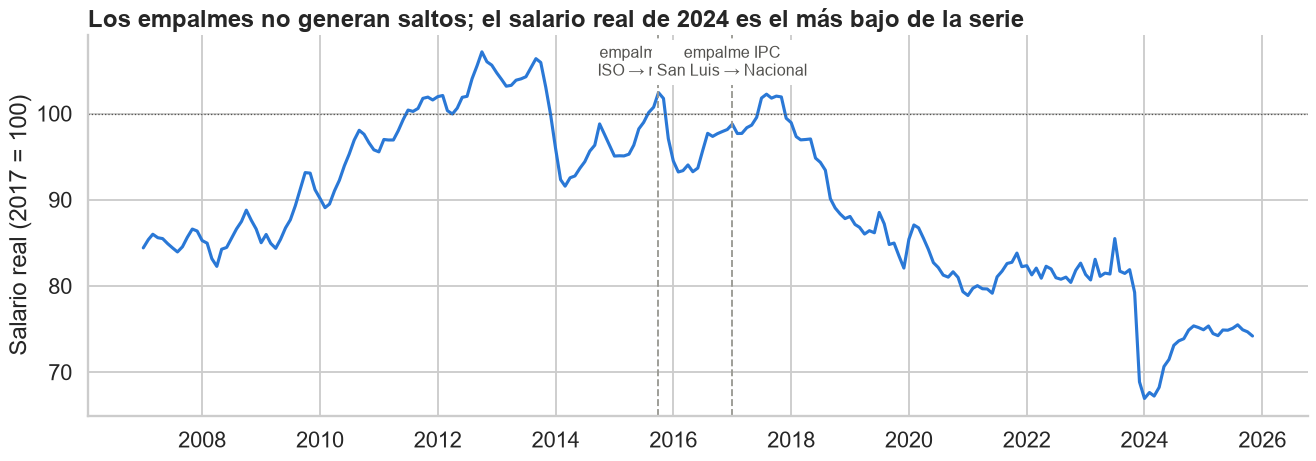

In [8]:
fig, ax = plt.subplots(figsize=(15, 5.5))
ax.plot(df.index, df.salario_real, color=AZUL, lw=2.5)
for fecha, texto in [("2015-10-01", "empalme salario\nISO → registrado"), ("2017-01-01", "empalme IPC\nSan Luis → Nacional")]:
    ax.axvline(pd.Timestamp(fecha), color=GRIS, ls="--", lw=1.5)
    ax.text(pd.Timestamp(fecha), 108, texto, fontsize=13, color="#52514e", ha="center", va="top",
            bbox=dict(facecolor="white", edgecolor="none"))
ax.axhline(100, color="#52514e", lw=1, ls=":")
ax.set(title="Los empalmes no generan saltos; el salario real de 2024 es el más bajo de la serie",
       ylabel="Salario real (2017 = 100)", xlabel="")
plt.tight_layout(); plt.show()

### 2.c Faltantes de pobreza
`pobreza` (EPH semestral) **no tiene datos de 2007-S2 a 2016-S1**: el INDEC no publicó pobreza en esos años. Son ~108 meses (48 %), muy por encima del 5 % que permite eliminar filas, y no es un faltante al azar (falta un período entero), así que **imputar no corresponde**. **Decisión:** pobreza se usa solo en el EDA, no entra al modelo.

Además, el archivo crudo trae un último valor fechado **2026-07** (segundo semestre de 2026, que todavía no terminó): es un dato dudoso. No afecta al dataset mensual, que termina en 2025-11 junto con la EOH.

In [9]:
pob = pd.read_csv(raw / "api_pobreza_semestral.csv", index_col="indice_tiempo", parse_dates=True).iloc[:, 0] * 100
print("Años con pobreza faltante en el dataset mensual:")
print(df.pobreza.isna().groupby(df.index.year).sum().loc[lambda x: x > 0].to_dict())
print("\nÚltimos valores del archivo crudo:")
print(pob.tail(4).round(1).to_string())

Años con pobreza faltante en el dataset mensual:
{2007: 6, 2008: 12, 2009: 12, 2010: 12, 2011: 12, 2012: 12, 2013: 12, 2014: 12, 2015: 12, 2016: 6}

Últimos valores del archivo crudo:
indice_tiempo
2025-01-01   38.10
2025-07-01   31.60
2026-01-01   28.20
2026-07-01   32.30


## 3. Los cinco tipos de EDA
### Tipo 1 · Univariante no gráfico
Una variable en números: tendencia central, dispersión y posición; frecuencias para las categóricas.

In [10]:
num = ["viajeros_residentes", "inflacion_interanual", "salario_real", "tipo_cambio_real",
       "emae_interanual", "desocupacion", "pobreza"]
df[num].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
viajeros_residentes,227.00,"1,210,279.80","330,442.30",0.00,"1,085,946.50","1,245,606.00","1,386,152.50","1,800,900.00"
inflacion_interanual,227.00,49.80,53.10,7.90,23.90,31.40,50.40,289.40
salario_real,227.00,89.50,9.50,66.90,82.20,88.40,97.60,107.20
tipo_cambio_real,227.00,124.90,30.10,85.50,102.00,113.50,144.20,220.50
emae_interanual,227.00,1.60,6.40,-25.50,-2.30,1.30,5.90,31.50
desocupacion,227.00,8.00,1.40,5.70,7.10,7.60,8.70,13.10
pobreza,119.00,35.80,6.50,25.70,31.00,36.50,40.40,52.90


In [11]:
s = df.loc[~df.pandemia, "viajeros_residentes"]
print("Viajeros residentes por mes (sin pandemia)")
print(f"media {s.mean():,.0f}  mediana {s.median():,.0f}  desvío {s.std():,.0f}  "
      f"IQR {s.quantile(.75) - s.quantile(.25):,.0f}  CV {s.std() / s.mean():.0%}")

Viajeros residentes por mes (sin pandemia)
media 1,282,816  mediana 1,266,160  desvío 210,427  IQR 269,567  CV 16%


In [12]:
# Categóricas de EVyTH: frecuencia ponderada (por pondera), no conteo de filas
ponderado = lambda col: (ev.groupby(col).pondera.sum() / ev.pondera.sum() * 100).round(1)
pd.DataFrame({"% de filas": (ev.quintil.value_counts(normalize=True).sort_index() * 100).round(1),
              "% de turistas (ponderado)": ponderado("quintil")}).rename_axis("quintil de ingreso")

,% de filas,% de turistas (ponderado)
quintil de ingreso,,
1,4.00,7.50
2,7.70,12.20
3,13.70,17.80
4,21.60,22.40
5,53.00,40.10


**Qué leemos:** un mes típico (sin pandemia) tiene ~1,28 millones de viajeros residentes, con un desvío de ~200 mil (CV ≈ 16 %). La inflación tiene una media (~50 %) muy por encima de su mediana: la arrastran pocos meses extremos. En EVyTH el quintil 5 son el 53 % de las filas pero el 40 % de los turistas: **sin `pondera` sobrerrepresentaríamos a los hogares ricos.**

**Qué se nos escapa:** la **forma** de la distribución. Media y desvío no dicen si hay dos picos (temporada alta y baja) ni dónde están los extremos.

### Tipo 2 · Univariante gráfico
La forma: simetría, sesgo, picos y extremos. Histograma y boxplot **lado a lado**, con media y mediana; después, la distribución por grupo.

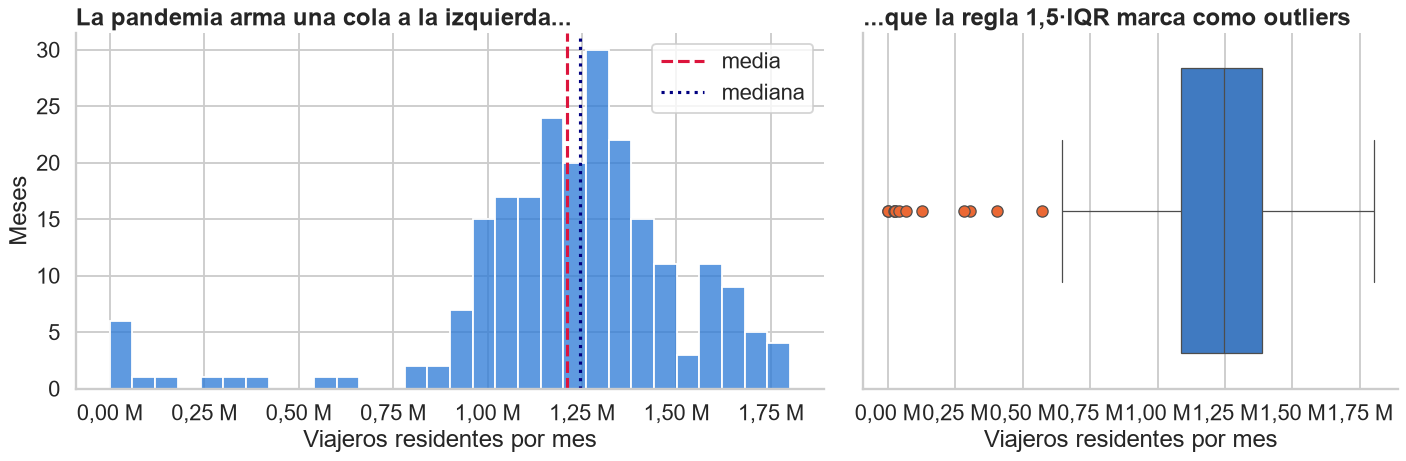

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
sns.histplot(df.viajeros_residentes, bins=30, ax=ax[0], color=AZUL)
ax[0].axvline(df.viajeros_residentes.mean(), color="crimson", ls="--", lw=2.5, label="media")
ax[0].axvline(df.viajeros_residentes.median(), color="navy", ls=":", lw=2.5, label="mediana")
ax[0].legend(); ax[0].xaxis.set_major_formatter(MILES)
ax[0].set(title="La pandemia arma una cola a la izquierda...", xlabel="Viajeros residentes por mes", ylabel="Meses")
sns.boxplot(x=df.viajeros_residentes, ax=ax[1], color=AZUL, whis=1.5, flierprops=dict(markerfacecolor=NARANJA, markersize=9))
ax[1].xaxis.set_major_formatter(MILES)
ax[1].set(title="...que la regla 1,5·IQR marca como outliers", xlabel="Viajeros residentes por mes")
plt.tight_layout(); plt.show()

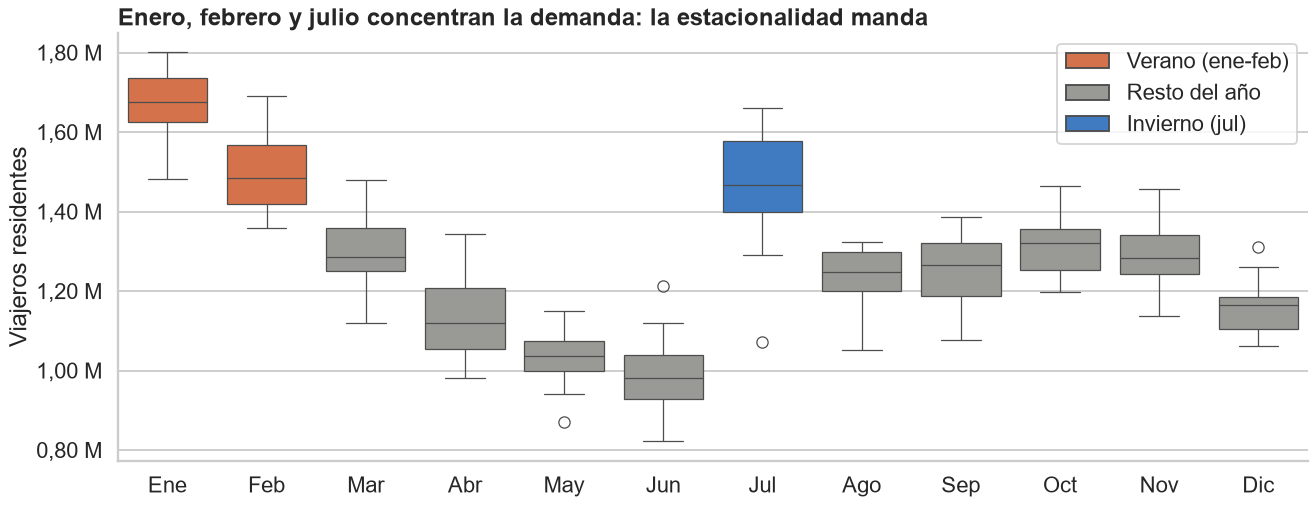

In [14]:
fig, ax = plt.subplots(figsize=(15, 6))
sns.boxplot(data=df[~df.pandemia], x="mes", y="viajeros_residentes", hue="temporada", palette=PALETA_TEMP,
            dodge=False, ax=ax, whis=1.5)
ax.set_xticks(range(12), MESES); ax.yaxis.set_major_formatter(MILES)
ax.set(title="Enero, febrero y julio concentran la demanda: la estacionalidad manda",
       xlabel="", ylabel="Viajeros residentes")
ax.legend(title="", loc="upper right")
plt.tight_layout(); plt.show()

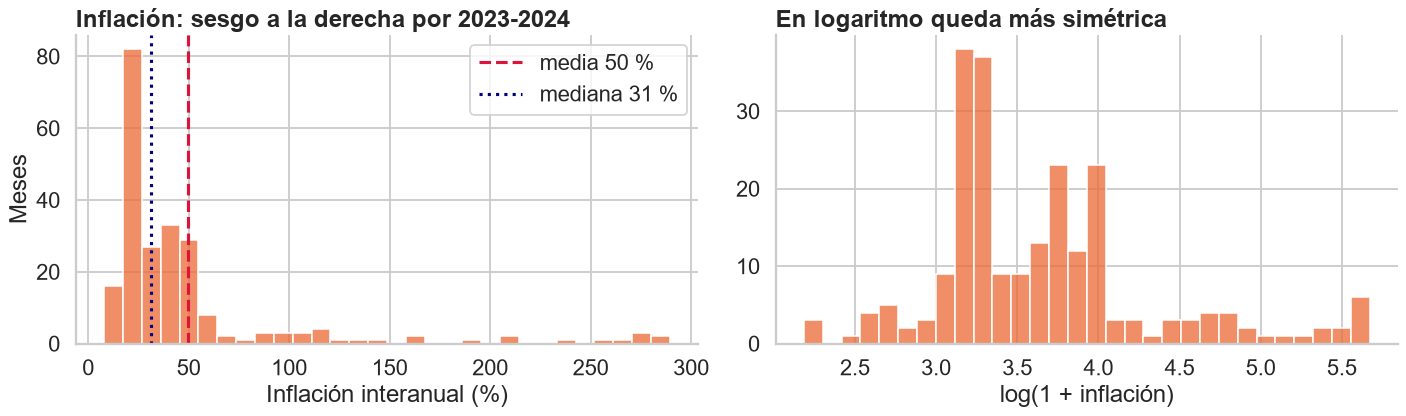

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
inf = df.inflacion_interanual
sns.histplot(inf, bins=30, ax=ax[0], color=NARANJA)
ax[0].axvline(inf.mean(), color="crimson", ls="--", lw=2.5, label=f"media {inf.mean():.0f} %")
ax[0].axvline(inf.median(), color="navy", ls=":", lw=2.5, label=f"mediana {inf.median():.0f} %")
ax[0].legend(); ax[0].set(title="Inflación: sesgo a la derecha por 2023-2024", xlabel="Inflación interanual (%)", ylabel="Meses")
sns.histplot(np.log1p(inf), bins=30, ax=ax[1], color=NARANJA)
ax[1].set(title="En logaritmo queda más simétrica", xlabel="log(1 + inflación)", ylabel="")
plt.tight_layout(); plt.show()

**Qué leemos:** sin pandemia, la distribución de viajeros es bastante simétrica, pero **mezcla meses de temporada alta y baja**: enero (~1,7 M) casi duplica a junio (~1,0 M). Los 12 outliers por la regla 1,5·IQR son todos meses de pandemia: un outlier no es un error, pero acá sí es un caso no representativo. La inflación tiene un sesgo fuerte a la derecha (2023–2024 llegaron a ~290 %): para el modelo conviene usarla en logaritmo (`inflacion_log`).

**Qué se nos escapa:** cómo se relacionan los viajeros con la economía. Una variable sola no responde la hipótesis.

### Tipo 3 · Multivariante no gráfico
Relaciones en números: correlación de Pearson, tabla de contingencia y `groupby().agg()`.

In [16]:
sin_pandemia = df[~df.pandemia]
corr_niveles = sin_pandemia[num].corr()["viajeros_residentes"].drop("viajeros_residentes")

var = ["var_viajeros", "salario_real_var", "inflacion_log", "desocupacion_var", "tipo_cambio_real_var", "emae_interanual"]
usable = df[df.usable]
corr_var = usable[var].corr()["var_viajeros"].drop("var_viajeros")
print("Correlación de Pearson con los VIAJEROS (niveles, sin pandemia):")
print(corr_niveles.round(2).to_string())
print("\nCorrelación con la VARIACIÓN INTERANUAL de viajeros (meses utilizables):")
print(corr_var.round(2).to_string())

Correlación de Pearson con los VIAJEROS (niveles, sin pandemia):
inflacion_interanual   -0.06
salario_real            0.07
tipo_cambio_real       -0.07
emae_interanual         0.03
desocupacion            0.09
pobreza                -0.19

Correlación con la VARIACIÓN INTERANUAL de viajeros (meses utilizables):
salario_real_var        0.47
inflacion_log          -0.34
desocupacion_var       -0.41
tipo_cambio_real_var   -0.33
emae_interanual         0.47


In [17]:
# Tabla de contingencia ponderada: % de turistas que se alojan en hotel, por quintil de ingreso
tabla = pd.crosstab(ev.quintil, ev.hotel, values=ev.pondera, aggfunc="sum", normalize="index") * 100
tabla.columns = ["Otro alojamiento (%)", "Hotel (%)"]
tabla.index = [f"Quintil {q}" for q in tabla.index]
tabla.round(1)

,Otro alojamiento (%),Hotel (%)
Quintil 1,82.60,17.40
Quintil 2,81.00,19.00
Quintil 3,77.30,22.70
Quintil 4,74.20,25.80
Quintil 5,71.20,28.80


In [18]:
# groupby.agg ponderado por región de destino
ev["hotel_pond"] = ev.hotel * ev.pondera
por_region = ev.groupby("region_destino").agg(viajes=("hotel", "size"), turistas=("pondera", "sum"),
                                               en_hotel=("hotel_pond", "sum"), noches_mediana=("noches", "median"))
por_region["% hotel"] = por_region.en_hotel / por_region.turistas * 100
por_region["% de los turistas"] = por_region.turistas / por_region.turistas.sum() * 100
por_region.index = por_region.index.map(REGIONES)
por_region[["viajes", "% de los turistas", "% hotel", "noches_mediana"]].sort_values("% hotel", ascending=False).round(1)

,viajes,% de los turistas,% hotel,noches_mediana
region_destino,,,,
Patagonia,24922,7.80,37.90,4.00
CABA,12063,3.10,36.10,4.00
Cuyo,21099,7.40,33.70,3.00
Centro,39699,13.40,30.10,3.00
Litoral,35446,17.60,24.70,3.00
Norte,38522,12.00,24.50,3.00
PBA resto,66251,36.50,19.20,4.00
Partidos del GBA,4065,2.10,2.00,3.00


**Qué leemos:** en **niveles**, la correlación de los viajeros con la macro es casi nula (|r| < 0,2): la estacionalidad domina la varianza y tapa todo lo demás. En cambio, si comparamos **cada mes contra el mismo mes del año anterior**, aparece la relación esperada: más salario real y más actividad → más viajeros (r ≈ +0,47); más desocupación, inflación o un tipo de cambio más caro → menos (r ≈ −0,33 a −0,41). Por eso el modelo predice la **variación interanual**. En EVyTH, el % de turistas que elige hotel sube con el ingreso: **17 % en el quintil 1 contra 29 % en el quintil 5**. Patagonia, CABA y Cuyo son los destinos más "hoteleros" (34–38 % en hotel); el resto de la provincia de Buenos Aires, el destino más visitado, solo 19 %.

**Qué se nos escapa:** un coeficiente es un promedio de toda la nube. No dice si la relación es lineal, si la arrastran unos pocos años, ni si se mantiene dentro de cada temporada.

### Tipo 4 · Multivariante gráfico
Dispersión y series en el tiempo (línea para muchos períodos), con una tercera variable por color. Global vs. por grupo.

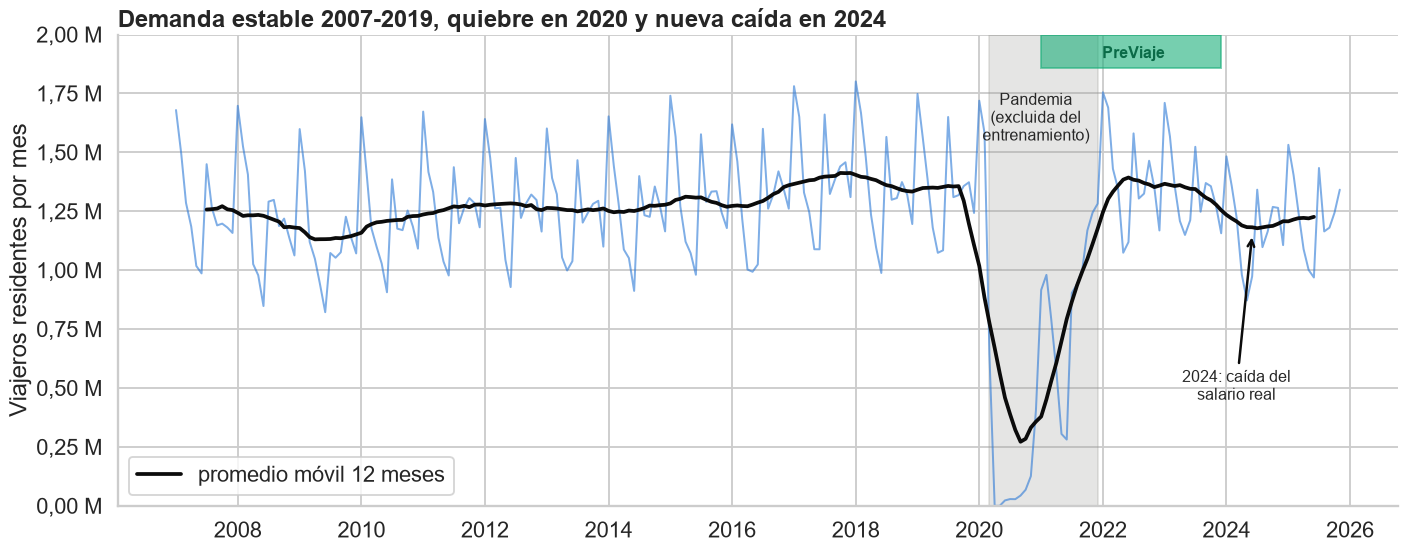

In [19]:
fig, ax = plt.subplots(figsize=(16, 6.5))
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color=GRIS, alpha=.25)
ax.axvspan(pd.Timestamp("2021-01-01"), pd.Timestamp("2023-12-01"), ymin=.93, ymax=1, color=VERDE, alpha=.6)
ax.plot(df.index, df.viajeros_residentes, color=AZUL, lw=1.6, alpha=.6)
anual = df.viajeros_residentes.rolling(12, center=True).mean()
ax.plot(df.index, anual, color="#0b0b0b", lw=3, label="promedio móvil 12 meses")
ax.text(pd.Timestamp("2020-12-01"), 1_550_000, "Pandemia\n(excluida del\nentrenamiento)", ha="center", fontsize=13)
ax.text(pd.Timestamp("2022-07-01"), 1_900_000, "PreViaje", ha="center", fontsize=13, color="#0b6b48", weight="bold")
ax.annotate("2024: caída del\nsalario real", xy=(pd.Timestamp("2024-06-01"), 1_150_000),
            xytext=(pd.Timestamp("2024-03-01"), 450_000), ha="center", fontsize=13,
            arrowprops=dict(arrowstyle="->", color="#0b0b0b", lw=2))
ax.yaxis.set_major_formatter(MILES); ax.set_ylim(0, 2_000_000)
ax.set(title="Demanda estable 2007-2019, quiebre en 2020 y nueva caída en 2024", ylabel="Viajeros residentes por mes")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

In [20]:
anios = df[~df.pandemia].groupby("anio").agg(viajeros=("viajeros_residentes", "sum"),
                                             salario_real=("salario_real", "mean"),
                                             inflacion=("inflacion_interanual", "mean"))
anios.loc[[2017, 2019, 2022, 2023, 2024]].assign(viajeros=lambda d: d.viajeros / 1e6).round(1) \
     .rename(columns={"viajeros": "viajeros (M)", "inflacion": "inflación (%)"})

,viajeros (M),salario_real,inflación (%)
anio,,,
2017,16.80,100.00,23.90
2019,16.30,86.00,53.60
2022,16.60,81.50,70.70
2023,16.10,80.70,127.90
2024,14.10,71.50,236.80


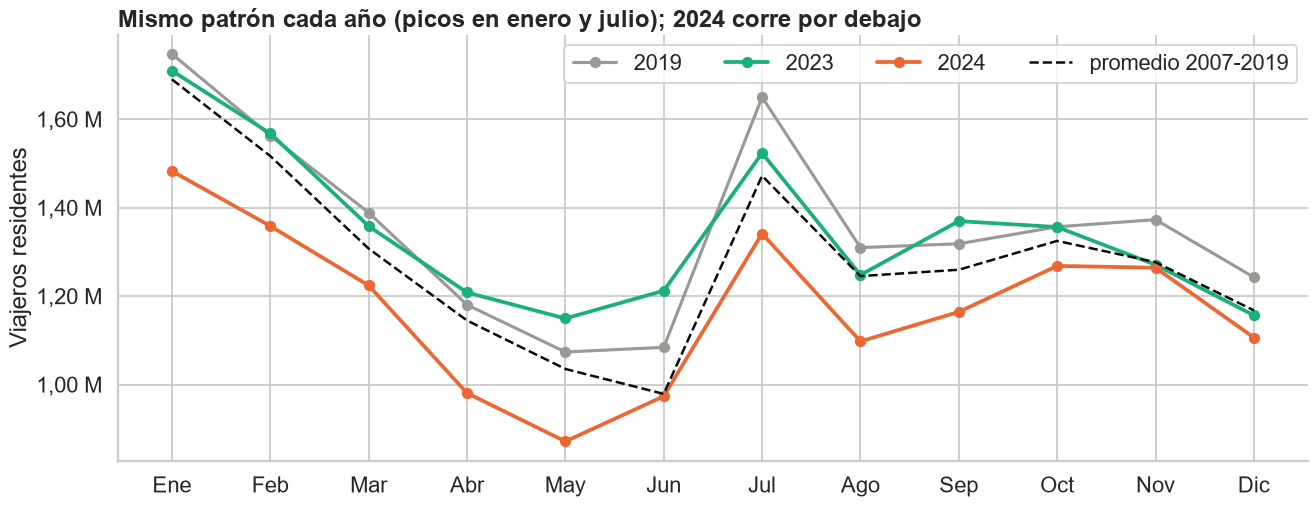

In [21]:
fig, ax = plt.subplots(figsize=(15, 6))
estacional = sin_pandemia.groupby(["mes", "anio"]).viajeros_residentes.sum().unstack()
for anio, color, lw in [(2019, GRIS, 2.5), (2023, VERDE, 3), (2024, NARANJA, 3)]:
    ax.plot(range(1, 13), estacional[anio], marker="o", color=color, lw=lw, ms=8, label=str(anio))
ax.plot(range(1, 13), estacional.drop(columns=[2023, 2024, 2025]).mean(axis=1), color="#0b0b0b", ls="--", lw=2,
        label="promedio 2007-2019")
ax.set_xticks(range(1, 13), MESES); ax.yaxis.set_major_formatter(MILES)
ax.set(title="Mismo patrón cada año (picos en enero y julio); 2024 corre por debajo", ylabel="Viajeros residentes")
ax.legend(ncol=4, loc="upper right")
plt.tight_layout(); plt.show()

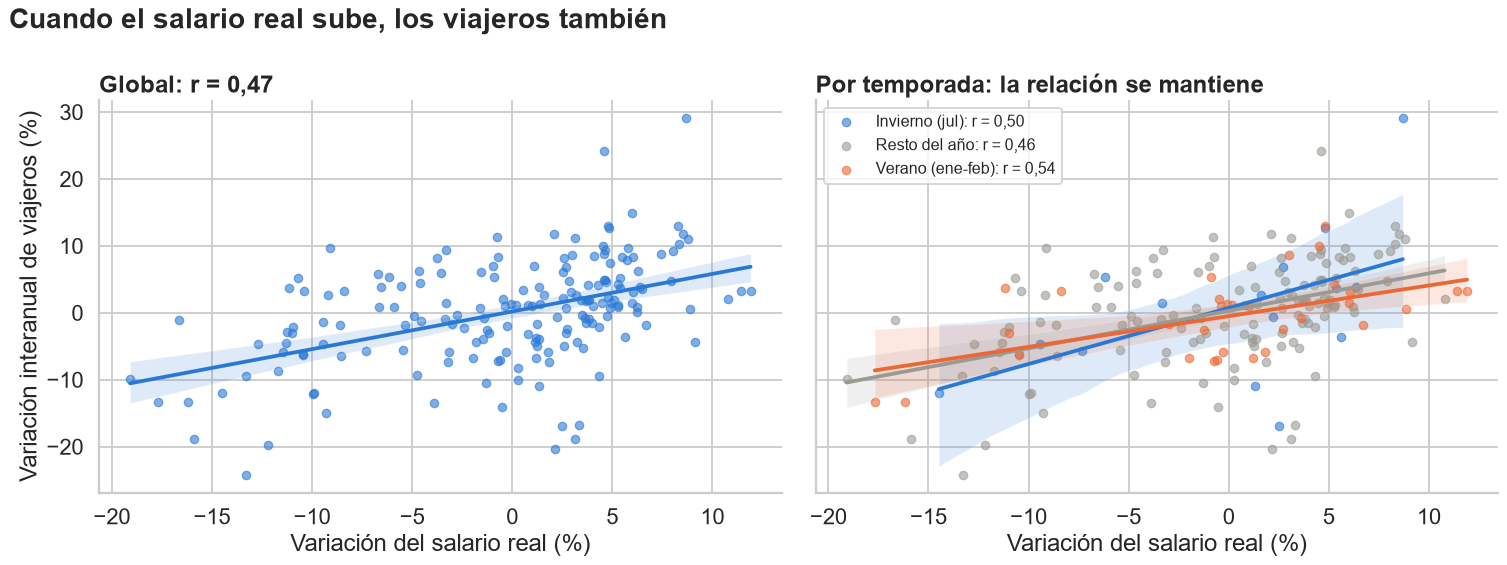

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), sharey=True)
x, y = "salario_real_var", "var_viajeros"
sns.regplot(data=usable, x=x, y=y, ax=ax[0], color=AZUL, scatter_kws=dict(s=45, alpha=.6), line_kws=dict(lw=3))
ax[0].set(title=f"Global: r = {coma(usable[x].corr(usable[y]))}", xlabel="Variación del salario real (%)",
          ylabel="Variación interanual de viajeros (%)")
for temp, g in usable.groupby("temporada"):
    sns.regplot(data=g, x=x, y=y, ax=ax[1], color=PALETA_TEMP[temp], scatter_kws=dict(s=45, alpha=.6),
                line_kws=dict(lw=3), label=f"{temp}: r = {coma(g[x].corr(g[y]))}")
ax[1].set(title="Por temporada: la relación se mantiene", xlabel="Variación del salario real (%)", ylabel="")
ax[1].legend(fontsize=13, loc="upper left")
fig.suptitle("Cuando el salario real sube, los viajeros también", fontsize=22, weight="bold", x=.01, ha="left")
plt.tight_layout(); plt.show()

**Chequeo de Paradoja de Simpson.** Hacemos la misma comparación global vs. por grupo, pero en **niveles** (viajeros del mes vs. salario real del mes):

Global (todos los meses juntos): r = 0.07
temporada
Invierno (jul)     0.29
Resto del año      0.14
Verano (ene-feb)   0.22


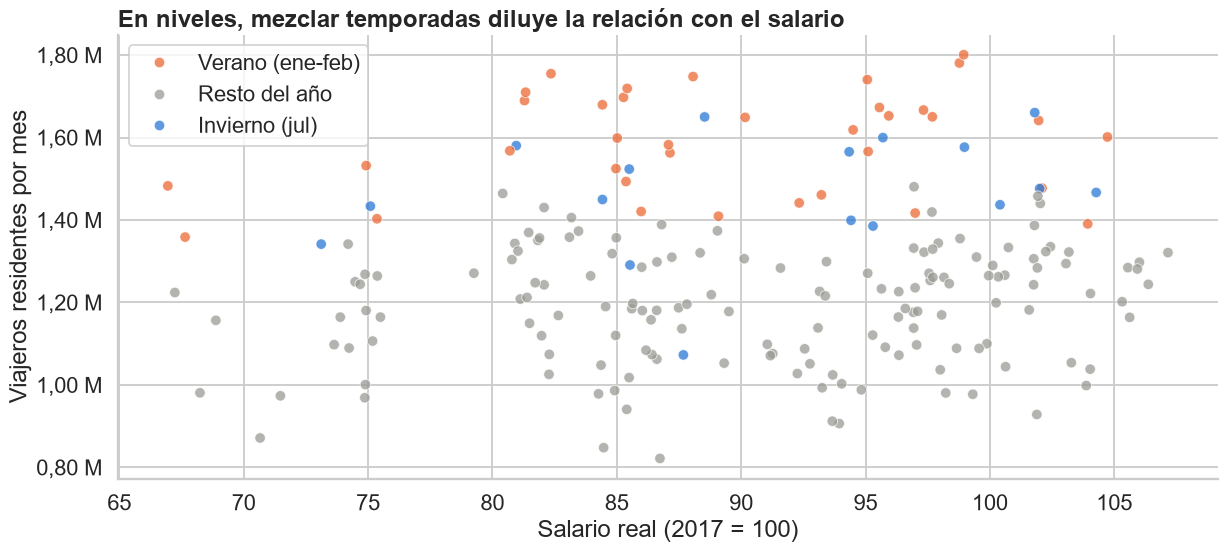

In [23]:
r_global = sin_pandemia.viajeros_residentes.corr(sin_pandemia.salario_real)
r_grupo = sin_pandemia.groupby("temporada")[["viajeros_residentes", "salario_real"]].corr().xs("salario_real", level=1).viajeros_residentes
print(f"Global (todos los meses juntos): r = {r_global:.2f}")
print(r_grupo.round(2).rename("r dentro de cada temporada").to_string())

fig, ax = plt.subplots(figsize=(14, 6.5))
sns.scatterplot(data=sin_pandemia, x="salario_real", y="viajeros_residentes", hue="temporada", palette=PALETA_TEMP,
                s=70, alpha=.75, ax=ax)
ax.yaxis.set_major_formatter(MILES)
ax.set(title="En niveles, mezclar temporadas diluye la relación con el salario",
       xlabel="Salario real (2017 = 100)", ylabel="Viajeros residentes por mes")
ax.legend(title="")
plt.tight_layout(); plt.show()

**Qué leemos:** la serie muestra cuatro etapas: estabilidad 2007–2019 (~15–16 M de viajeros por año, pico de 1,8 M en enero de 2018), el **quiebre de 2020**, la recuperación de 2022–2023 y la **caída de 2024**. El dato que más llama la atención: **2022 tuvo 16,6 M de viajeros, más que 2019 (16,3 M), con un salario real más bajo (81 vs. 86)**. Eso no lo explica la macro: es el efecto del **PreViaje** (programa del Gobierno 2021–2023 que reintegraba el 50 % de los gastos turísticos). En 2024, sin PreViaje, con el salario real en su mínimo (71,5) e inflación de ~290 %, la demanda cayó 12 % (14,1 M).

**Paradoja de Simpson:** en niveles, mezclar todos los meses da r ≈ 0,07 ("el salario no importa"), pero dentro de cada temporada la relación es más fuerte (0,14 a 0,29): la estacionalidad agrupa los puntos en franjas y tapa la relación. No hay inversión de signo, pero sí un efecto enmascarado. En variaciones interanuales, en cambio, la relación es estable en todos los grupos (r ≈ 0,46–0,54). **Nunca cerrar un EDA con una matriz de correlación.**

**Qué se nos escapa:** con 3–4 dimensiones a la vez el gráfico se satura. Para ver todas las variables macro juntas necesitamos otra herramienta.

### Tipo 5 · Otros multivariantes
Muchas dimensiones a la vez: heatmap, burbujas y pairplot.

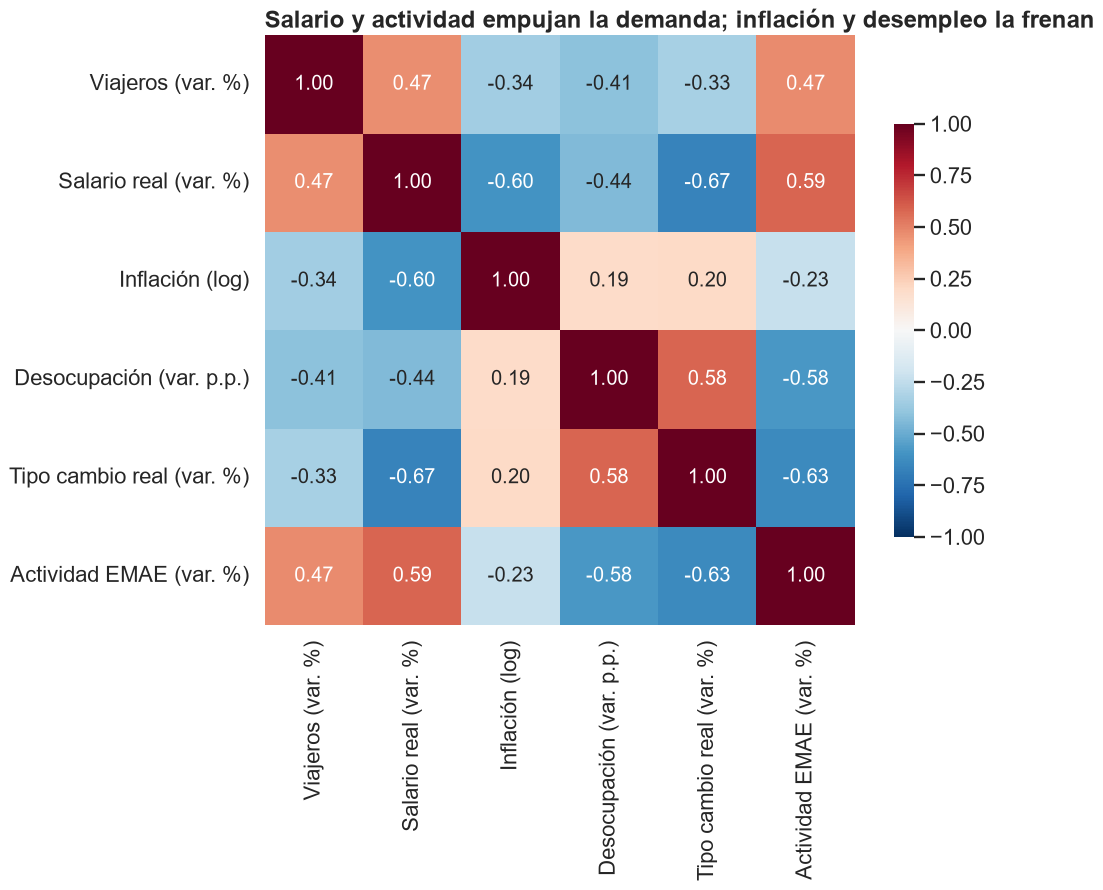

In [24]:
etiquetas = {"var_viajeros": "Viajeros (var. %)", "salario_real_var": "Salario real (var. %)",
             "inflacion_log": "Inflación (log)", "desocupacion_var": "Desocupación (var. p.p.)",
             "tipo_cambio_real_var": "Tipo cambio real (var. %)", "emae_interanual": "Actividad EMAE (var. %)"}
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(usable[var].corr().rename(index=etiquetas, columns=etiquetas), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, square=True, annot_kws={"size": 16}, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Salario y actividad empujan la demanda; inflación y desempleo la frenan", loc="left")
plt.tight_layout(); plt.show()

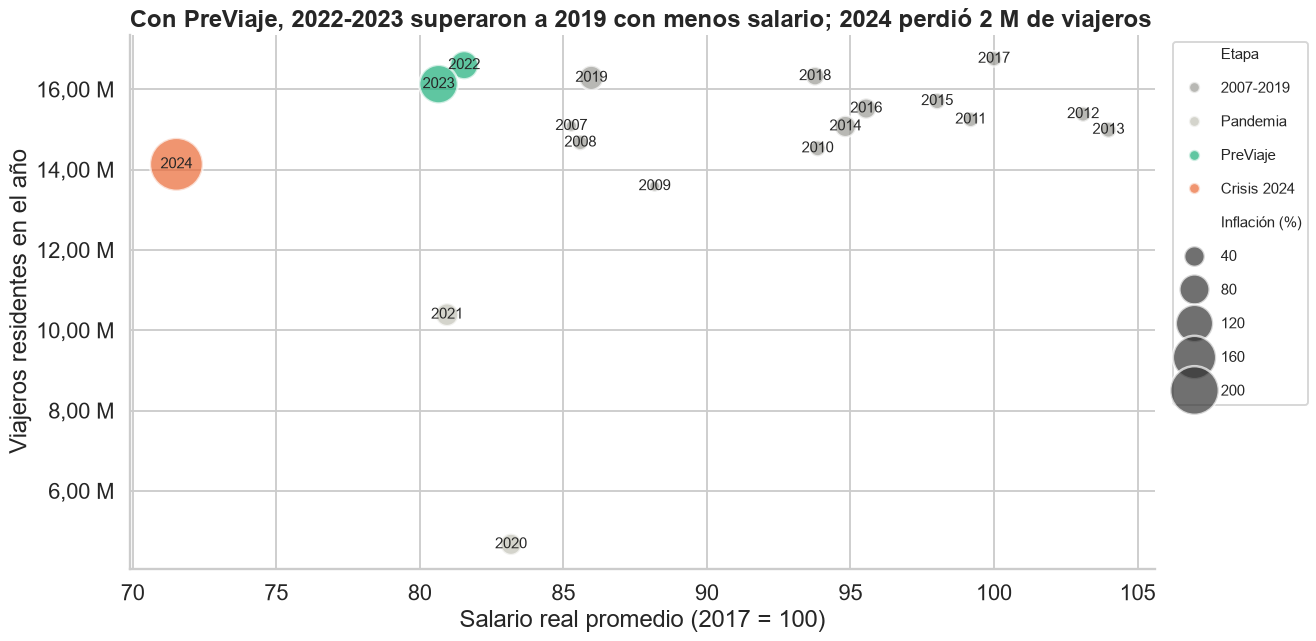

In [25]:
anios_todos = df.groupby("anio").agg(viajeros=("viajeros_residentes", "sum"), salario_real=("salario_real", "mean"),
                                     inflacion=("inflacion_interanual", "mean")).loc[:2024]
anios_todos["etapa"] = np.select([anios_todos.index.isin([2020, 2021]), anios_todos.index.isin([2022, 2023]),
                                  anios_todos.index == 2024],
                                 ["Pandemia", "PreViaje", "Crisis 2024"], "2007-2019")
colores = {"2007-2019": GRIS, "Pandemia": "#c3c2b7", "PreViaje": VERDE, "Crisis 2024": NARANJA}
fig, ax = plt.subplots(figsize=(15, 7.5))
sns.scatterplot(data=anios_todos, x="salario_real", y="viajeros", hue="etapa", palette=colores, size="inflacion",
                sizes=(80, 1800), alpha=.7, edgecolor="white", linewidth=2, ax=ax, legend="brief")
for anio, fila in anios_todos.iterrows():
    ax.annotate(str(anio), (fila.salario_real, fila.viajeros), fontsize=12, ha="center", va="center")
ax.yaxis.set_major_formatter(MILES)
ax.set(title="Con PreViaje, 2022-2023 superaron a 2019 con menos salario; 2024 perdió 2 M de viajeros",
       xlabel="Salario real promedio (2017 = 100)", ylabel="Viajeros residentes en el año")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [l.replace("etapa", "Etapa").replace("inflacion", "Inflación (%)") for l in labels],
          bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=12, labelspacing=1.3)
plt.tight_layout(); plt.show()

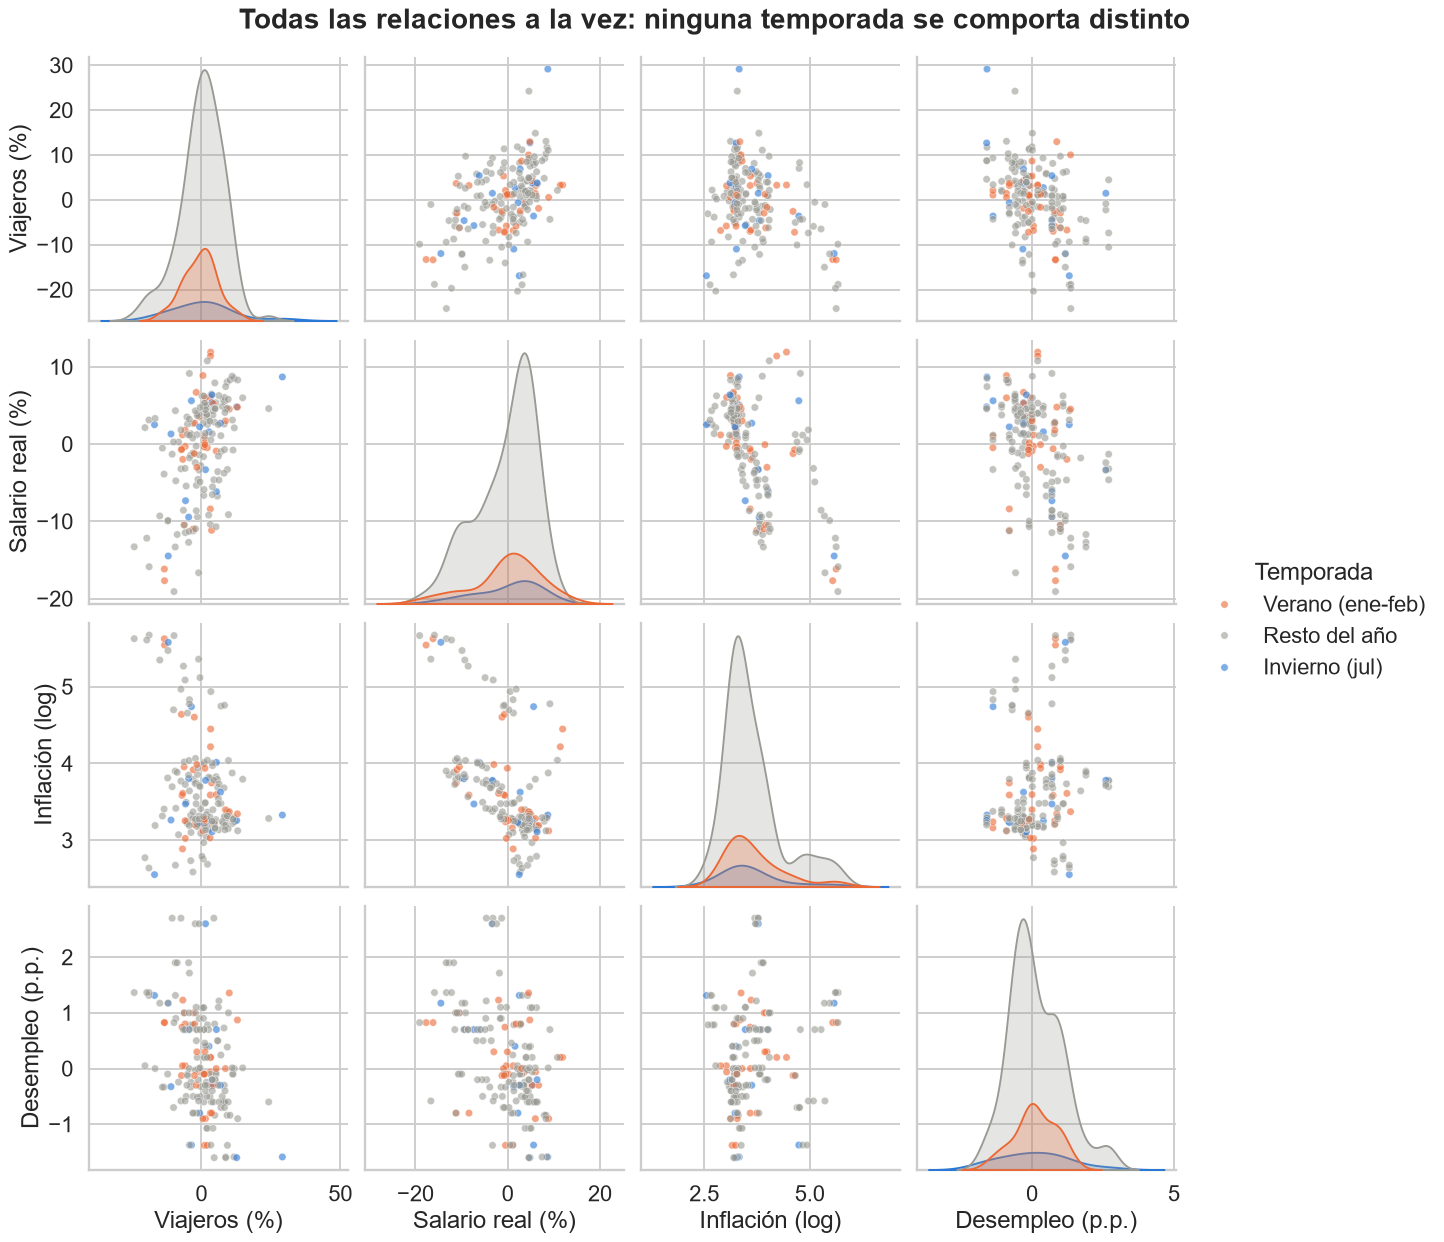

In [26]:
cortas = {"var_viajeros": "Viajeros (%)", "salario_real_var": "Salario real (%)",
          "inflacion_log": "Inflación (log)", "desocupacion_var": "Desempleo (p.p.)"}
g = sns.pairplot(usable[list(cortas) + ["temporada"]].rename(columns=cortas), hue="temporada", palette=PALETA_TEMP,
                 plot_kws=dict(s=35, alpha=.6), height=3.4)
g._legend.set_title("Temporada")
g.figure.suptitle("Todas las relaciones a la vez: ninguna temporada se comporta distinto", y=1.02, fontsize=22,
                  weight="bold")
plt.show()

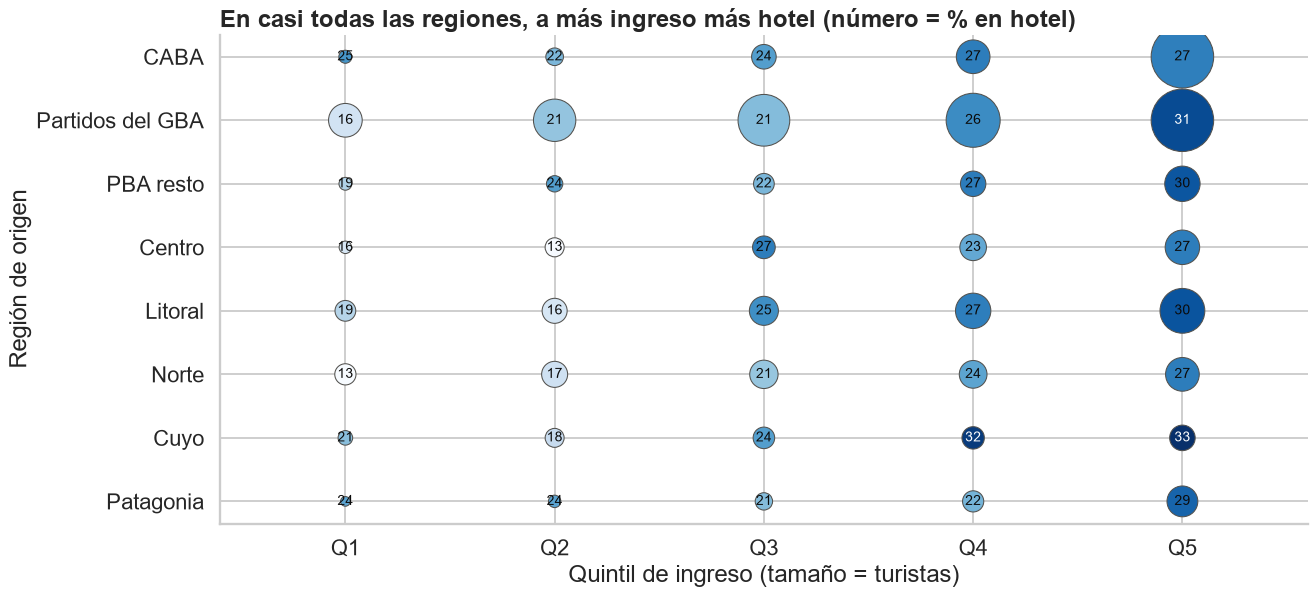

In [27]:
# Burbujas EVyTH: quién elige hotel, por región de origen y quintil
grupo = ev.groupby(["region_origen", "quintil"]).agg(turistas=("pondera", "sum"), en_hotel=("hotel_pond", "sum"))
grupo["pct_hotel"] = grupo.en_hotel / grupo.turistas * 100
grupo = grupo.reset_index()
grupo["region"] = grupo.region_origen.map(REGIONES)
fig, ax = plt.subplots(figsize=(15, 7))
sns.scatterplot(data=grupo, x="quintil", y="region", size="turistas", hue="pct_hotel", palette="Blues",
                sizes=(60, 2500), edgecolor="#52514e", ax=ax, legend=False)
for _, f in grupo.iterrows():
    ax.text(f.quintil, f.region, f"{f.pct_hotel:.0f}", ha="center", va="center", fontsize=11,
            color="white" if f.pct_hotel > 30 else "#0b0b0b")
ax.set_xticks(range(1, 6), [f"Q{q}" for q in range(1, 6)]); ax.set_xlim(.4, 5.6)
ax.set(title="En casi todas las regiones, a más ingreso más hotel (número = % en hotel)",
       xlabel="Quintil de ingreso (tamaño = turistas)", ylabel="Región de origen")
plt.tight_layout(); plt.show()

**Qué leemos:** el heatmap resume la hipótesis: salario real y actividad correlacionan positivo con la demanda; inflación, desocupación y tipo de cambio real, negativo. Además, las macro están **correlacionadas entre sí** (por ejemplo, salario real e inflación): para el modelo no son información independiente. Las burbujas por año muestran que **2022–2023 (PreViaje) quedan arriba de 2019 con un salario real más bajo**: algo que la macro no explica. En 2024, sin PreViaje, con el salario real en su mínimo y la inflación más alta (la burbuja más grande), la demanda pierde 2 M de viajeros. El pairplot confirma que las temporadas no se comportan distinto en variaciones (no hay Simpson ahí). En EVyTH, el quintil 5 usa hotel más que el quintil 1 **en todas las regiones de origen** (con algún salto intermedio, como Centro): no es un efecto de dónde vive la gente.

**Qué se nos escapa:** el detalle fino de cada par y, sobre todo, la **causalidad**: correlación no es causa. Eso lo encaramos con los modelos y su validación temporal.

## 4. Hallazgos clave (para la Gerencia Comercial y Técnica)

1. **La temporada manda.** Enero (~1,7 M de viajeros) casi duplica a junio (~1,0 M); febrero y julio (vacaciones de invierno) son los otros picos. Cualquier plan de personal, cupos y precios arranca por el calendario.
2. **2020 fue un quiebre, no un dato.** Abril y mayo de 2020 tuvieron 0 viajeros. La pandemia (2020-03 → 2021-12) se excluye del entrenamiento: es real, pero no enseña cómo responde la demanda a la economía.
3. **La economía mueve la demanda en la comparación interanual.** Cuando el salario real o la actividad suben, los viajeros suben contra el mismo mes del año anterior (r ≈ +0,47); con más desempleo o inflación, bajan. El modelo tiene que predecir la variación interanual, no el nivel.
4. **El PreViaje infló 2022–2023.** 2022 tuvo más viajeros que 2019 (16,6 M vs. 16,3 M) con un salario real más bajo. Las variables macro no capturan ese programa: el modelo lo va a subestimar y hay que decirlo.
5. **2024 mostró el riesgo.** Con el salario real en su mínimo histórico (66,9 en enero; 71,5 de promedio anual, 2017 = 100) e inflación de ~290 % en abril, los viajeros cayeron 12 % (14,1 M en el año). En un escenario pesimista, la demanda se resiente rápido.
6. **Los hogares de más ingreso son los clientes de hotel.** El 29 % de los turistas del quintil 5 se aloja en hotel, contra el 17 % del quintil 1, y en todas las regiones de origen el quintil 5 supera al quintil 1. Ese es el segmento a apuntar.
7. **Calidad documentada.** IPC y salario están empalmados (el IPC oficial 2007–2015 subestimaba la inflación); pobreza tiene 48 % de faltantes y solo se usa en el EDA; los datos de 2025 son provisorios.

## 5. Tabla de cierre

| Tipo | Qué responde | Qué no puede responder | En este TPO |
|---|---|---|---|
| 1 · Univariante no gráfico | Centro y dispersión | Forma de la distribución | Un mes típico ≈ 1,28 M de viajeros; sin `pondera` sobrerrepresentamos al quintil 5 |
| 2 · Univariante gráfico | Simetría, sesgo, picos | Relación con otras variables | Picos en enero y julio; outliers 1,5·IQR = pandemia; inflación sesgada → log |
| 3 · Multivariante no gráfico | Fuerza de la relación | Si se mantiene en subgrupos | En niveles r ≈ 0; en variación interanual r ≈ ±0,4; hotel 17 % (Q1) → 29 % (Q5) |
| 4 · Multivariante gráfico | Forma real de la relación por subgrupo | Más de 3–4 dimensiones | Quiebre 2020, PreViaje 2022–2023, caída 2024; la estacionalidad enmascara la relación en niveles |
| 5 · Otros multivariantes | Muchas variables de un vistazo | Detalle fino de cada par | Heatmap con los signos esperados; burbujas: PreViaje fuera de la regla; más ingreso → más hotel en todas las regiones |

**Moraleja:** cada tipo tapa algo que el siguiente destapa. El EDA, además, **fabricó las features** del modelo: mes (estacionalidad), variaciones interanuales de salario real, desocupación y tipo de cambio, inflación en logaritmo y la marca de pandemia.

**Próximo paso (CRISP-DM, fases 3 y 4):** `02_modelos.ipynb`.